In [4]:
#Archivo para ver la calidad de las imagenes
#Descarga librerias y lee el Archivo inventario.csv

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

# Rutas del proyecto
PROYECTO = Path("..")
RESULTADOS = PROYECTO / "Resultados"
GRAFICOS = PROYECTO / "Graficos"

# Cargar el inventario generado
df = pd.read_csv(RESULTADOS / "inventario.csv")
print(f"Imágenes cargadas: {len(df)}")
df.head()

Imágenes cargadas: 15339


,split,carpeta,emocion,archivo,etiqueta_csv,verificacion,legible,ancho,alto,modo_color,ruta
0,test,5,Tristeza,test_0001_aligned.jpg,5,Coincide,True,100,100,RGB,..\base_expresiones_faciales\DATASET\test\5\te...
1,test,1,Sorpresa,test_0002_aligned.jpg,1,Coincide,True,100,100,RGB,..\base_expresiones_faciales\DATASET\test\1\te...
2,test,4,Felicidad,test_0003_aligned.jpg,4,Coincide,True,100,100,RGB,..\base_expresiones_faciales\DATASET\test\4\te...
3,test,1,Sorpresa,test_0004_aligned.jpg,1,Coincide,True,100,100,RGB,..\base_expresiones_faciales\DATASET\test\1\te...
4,test,5,Tristeza,test_0005_aligned.jpg,5,Coincide,True,100,100,RGB,..\base_expresiones_faciales\DATASET\test\5\te...


In [5]:
def medir_calidad(ruta):
    img = cv2.imread(ruta)
    gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    b, g, r = cv2.split(img.astype(int))
    diferencia_color = (abs(r - g) + abs(g - b)).mean() / 2
    return {
        "brillo": gris.mean(),
        "contraste": gris.std(),
        "nitidez": cv2.Laplacian(gris, cv2.CV_64F).var(),
        "diferencia_color": diferencia_color,
    }

medidas = []
for ruta in df["ruta"]:
    medidas.append(medir_calidad(ruta))

df = pd.concat([df, pd.DataFrame(medidas)], axis=1)
df[["brillo", "contraste", "nitidez", "diferencia_color"]].describe().round(1)

,brillo,contraste,nitidez,diferencia_color
count,15339.0,15339.0,15339.0,15339.0
mean,122.8,49.1,806.1,24.1
std,34.4,15.1,1196.0,14.8
min,10.6,4.2,1.2,0.0
25%,98.7,38.2,174.8,15.1
50%,122.8,47.9,428.7,24.9
75%,147.2,58.9,980.3,33.3
max,238.6,113.5,36098.5,102.6


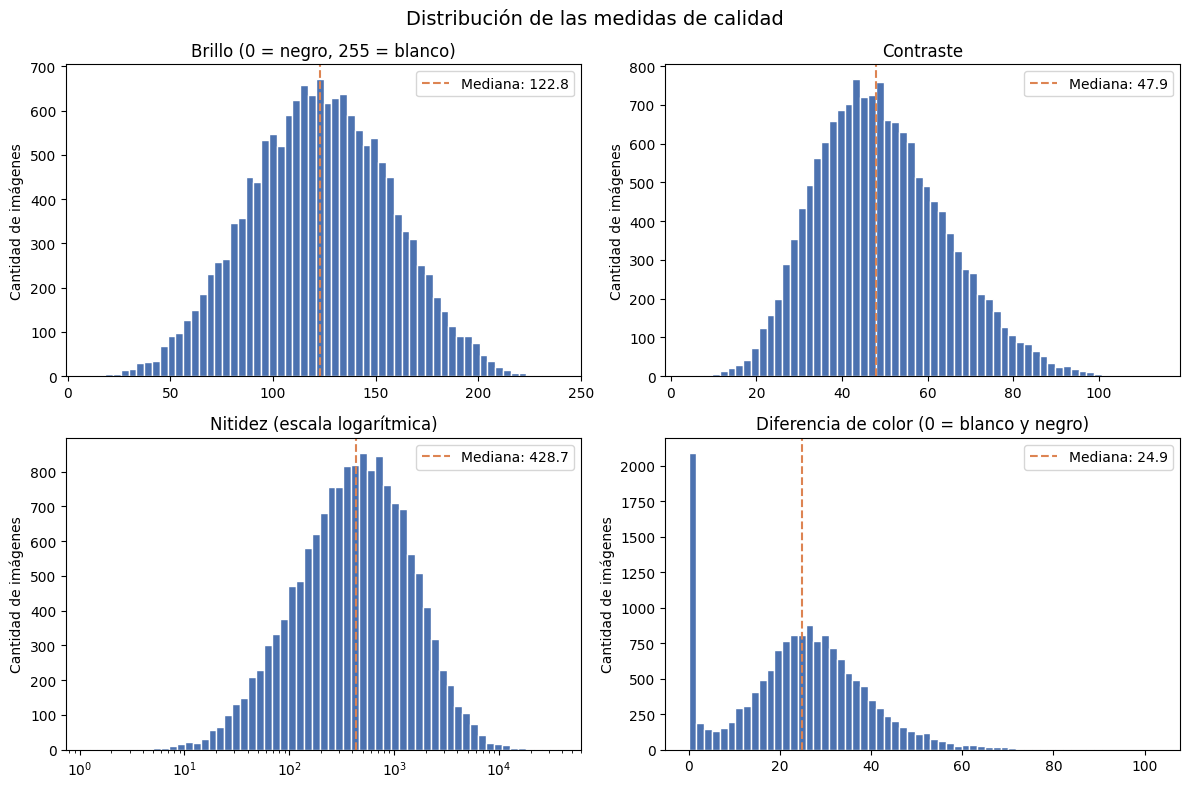

In [6]:
# Graficos
fig, ejes = plt.subplots(2, 2, figsize=(12, 8))

medidas_graficar = [
    ("brillo", "Brillo (0 = negro, 255 = blanco)", False),
    ("contraste", "Contraste", False),
    ("nitidez", "Nitidez (escala logarítmica)", True),
    ("diferencia_color", "Diferencia de color (0 = blanco y negro)", False),
]

for eje, (columna, titulo, escala_log) in zip(ejes.flat, medidas_graficar):
    datos = df[columna]
    if escala_log:
        bins = np.logspace(np.log10(datos.min()), np.log10(datos.max()), 60)
        eje.set_xscale("log")
    else:
        bins = 60
    eje.hist(datos, bins=bins, color="#4C72B0", edgecolor="white")
    eje.axvline(datos.median(), color="#DD8452", linestyle="--", label=f"Mediana: {datos.median():.1f}")
    eje.set_title(titulo)
    eje.set_ylabel("Cantidad de imágenes")
    eje.legend()

plt.suptitle("Distribución de las medidas de calidad", fontsize=14)
plt.tight_layout()
plt.savefig(GRAFICOS / "02_histogramas_calidad.png", dpi=150)
plt.show()

In [7]:
for limite in [1, 2, 3, 5, 8]:
    cantidad = (df["diferencia_color"] < limite).sum()
    print(f"diferencia_color < {limite}: {cantidad} imágenes ({cantidad / len(df) * 100:.1f}%)")

diferencia_color < 1: 2014 imágenes (13.1%)
diferencia_color < 2: 2122 imágenes (13.8%)
diferencia_color < 3: 2246 imágenes (14.6%)
diferencia_color < 5: 2411 imágenes (15.7%)
diferencia_color < 8: 2639 imágenes (17.2%)


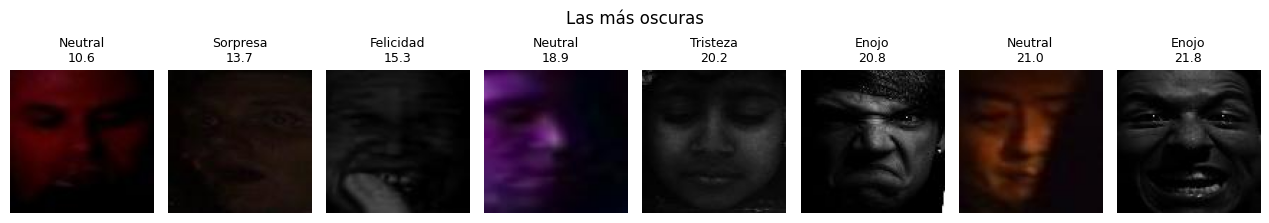

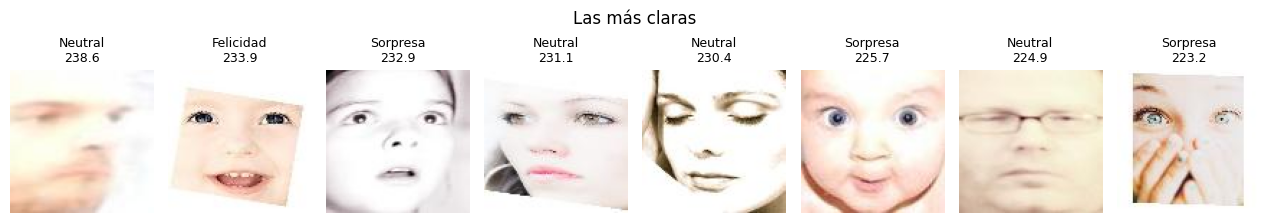

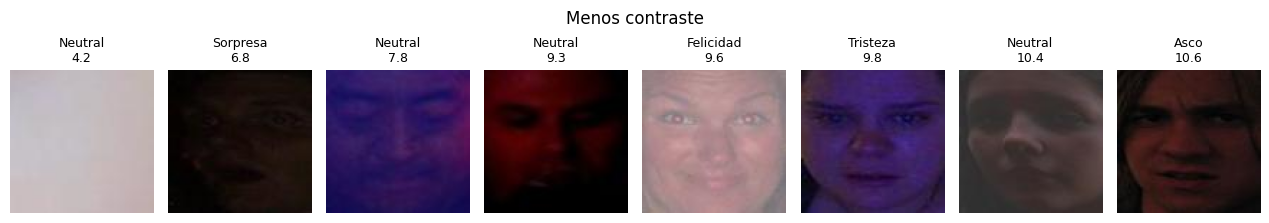

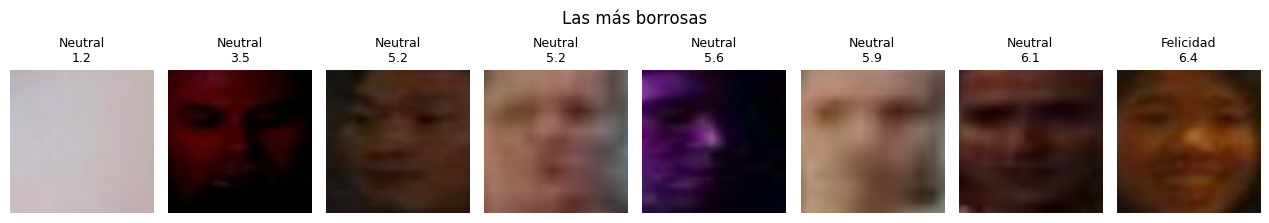

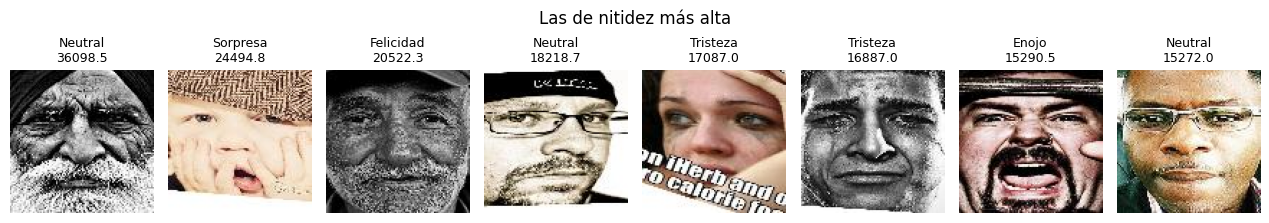

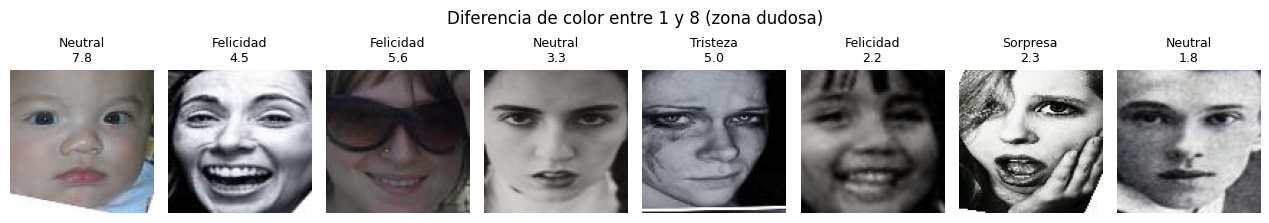

In [ ]:
# los peores ejemplos de cada cazo
def mostrar_ejemplos(datos, columna, titulo, cantidad=8):
    fig, ejes = plt.subplots(1, cantidad, figsize=(cantidad * 1.6, 2.4))
    for eje, (_, fila) in zip(ejes, datos.head(cantidad).iterrows()):
        img = cv2.cvtColor(cv2.imread(fila["ruta"]), cv2.COLOR_BGR2RGB)
        eje.imshow(img)
        eje.set_title(f"{fila['emocion']}\n{fila[columna]:.1f}", fontsize=9)
        eje.axis("off")
    plt.suptitle(titulo)
    plt.tight_layout()
    plt.show()

mostrar_ejemplos(df.sort_values("brillo"), "brillo", "Las más oscuras")
mostrar_ejemplos(df.sort_values("brillo", ascending=False), "brillo", "Las más claras")
mostrar_ejemplos(df.sort_values("contraste"), "contraste", "Menos contraste")
mostrar_ejemplos(df.sort_values("nitidez"), "nitidez", "Las más borrosas")
mostrar_ejemplos(df.sort_values("nitidez", ascending=False), "nitidez", "Las de nitidez más alta")

zona_gris = df[(df["diferencia_color"] >= 1) & (df["diferencia_color"] < 8)]
mostrar_ejemplos(zona_gris.sample(8, random_state=1), "diferencia_color", "Diferencia de color entre 1 y 8 (zona dudosa)")

muy_oscura            :    11 imágenes (0.1%)
sin_contraste         :     3 imágenes (0.0%)
muy_borrosa           :     2 imágenes (0.0%)
posible_inutilizable  :    13 imágenes (0.1%)
es_gris               :  2477 imágenes (16.1%)


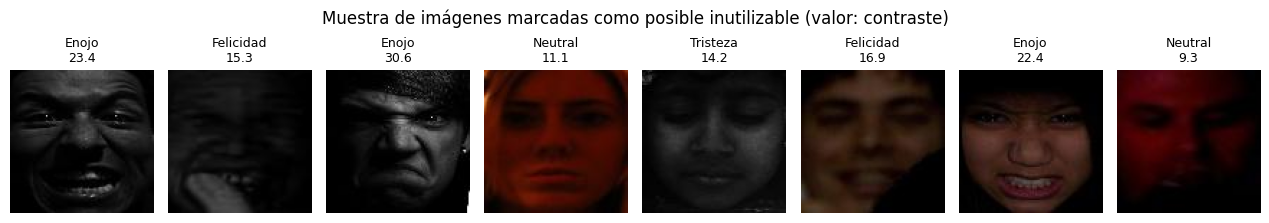

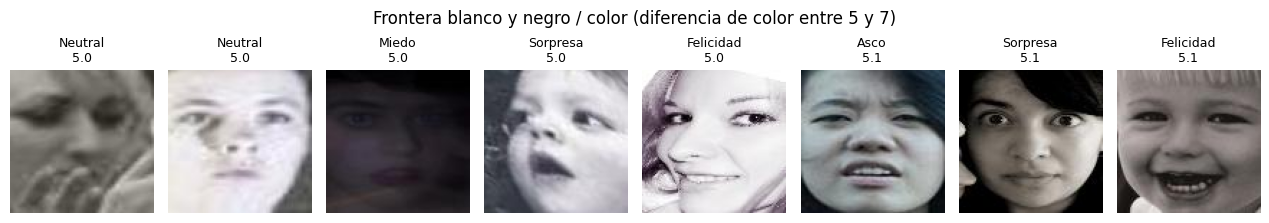

In [15]:
# Prueba limites de brillo, y calidad
LIMITE_OSCURA = 25
LIMITE_CONTRASTE = 8
LIMITE_BORROSA = 5
LIMITE_GRIS = 6

df["muy_oscura"] = df["brillo"] < LIMITE_OSCURA
df["sin_contraste"] = df["contraste"] < LIMITE_CONTRASTE
df["muy_borrosa"] = df["nitidez"] < LIMITE_BORROSA
df["es_gris"] = df["diferencia_color"] < LIMITE_GRIS
df["posible_inutilizable"] = df["muy_oscura"] | df["sin_contraste"] | df["muy_borrosa"]

for columna in ["muy_oscura", "sin_contraste", "muy_borrosa", "posible_inutilizable", "es_gris"]:
    cantidad = df[columna].sum()
    print(f"{columna:22}: {cantidad:5} imágenes ({cantidad / len(df) * 100:.1f}%)")

marcadas = df[df["posible_inutilizable"]]
mostrar_ejemplos(marcadas.sample(min(8, len(marcadas)), random_state=1), "contraste",
                 "Muestra de imágenes marcadas como posible inutilizable (valor: contraste)")

frontera_gris = df[(df["diferencia_color"] >= 5) & (df["diferencia_color"] < 7)]
mostrar_ejemplos(frontera_gris.sort_values("diferencia_color"), "diferencia_color",
                 "Frontera blanco y negro / color (diferencia de color entre 5 y 7)")

Imágenes a eliminar: 13

Por emoción:
emocion
Neutral      6
Enojo        3
Felicidad    2
Tristeza     1
Sorpresa     1
Name: count, dtype: int64


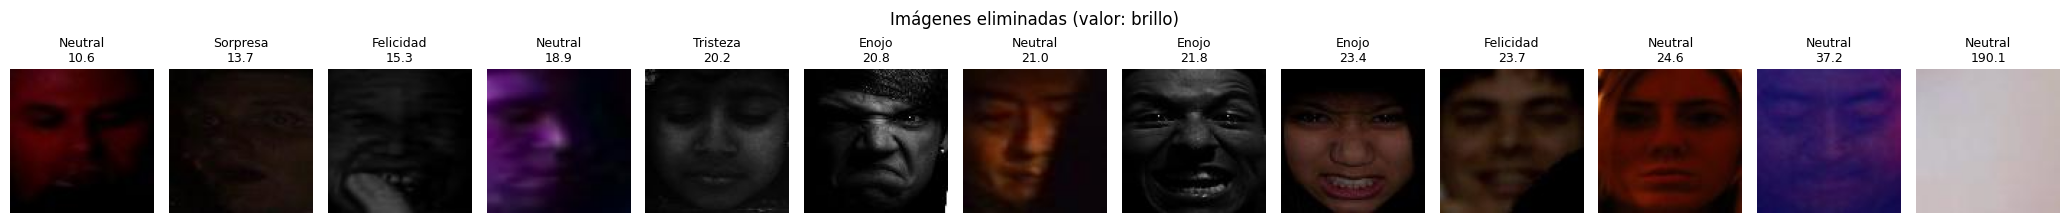

In [17]:
#elimina las mas oscuras y las que se ven mal
df["eliminada"] = df["posible_inutilizable"]

eliminadas = df[df["eliminada"]]
print(f"Imágenes a eliminar: {len(eliminadas)}")
print()
print("Por emoción:")
print(eliminadas["emocion"].value_counts())

mostrar_ejemplos(eliminadas.sort_values("brillo"), "brillo", "Imágenes eliminadas (valor: brillo)",
                 cantidad=len(eliminadas))

df_limpio = df[~df["eliminada"]].copy()


In [19]:
resumen = df.groupby("emocion").agg(
    imagenes=("archivo", "count"),
    brillo_mediana=("brillo", "median"),
    contraste_mediana=("contraste", "median"),
    nitidez_mediana=("nitidez", "median"),
)
print(resumen.round(1).sort_values("nitidez_mediana"))

peores_nitidez = df[df["nitidez"] < df["nitidez"].quantile(0.05)]
peores_contraste = df[df["contraste"] < df["contraste"].quantile(0.05)]

comparacion = pd.DataFrame({
    "% en el dataset": df["emocion"].value_counts(normalize=True) * 100,
    "% en el 5% más borroso": peores_nitidez["emocion"].value_counts(normalize=True) * 100,
    "% en el 5% con menos contraste": peores_contraste["emocion"].value_counts(normalize=True) * 100,
}).fillna(0).round(1).sort_values("% en el dataset", ascending=False)
comparacion


           imagenes  brillo_mediana  contraste_mediana  nitidez_mediana
emocion                                                                
Felicidad      5957           125.2               44.3            313.4
Neutral        3204           119.3               49.3            378.1
Asco            877           124.4               49.0            386.9
Tristeza       2460           121.4               49.7            582.1
Sorpresa       1619           131.3               49.7            639.9
Enojo           867           117.4               56.3            830.0
Miedo           355           101.4               56.7            921.2


,% en el dataset,% en el 5% más borroso,% en el 5% con menos contraste
emocion,,,
Felicidad,38.8,45.2,50.7
Neutral,20.9,34.2,22.4
Tristeza,16.0,6.3,13.2
Sorpresa,10.6,6.9,7.0
Asco,5.7,4.6,3.5
Enojo,5.7,1.8,2.1
Miedo,2.3,1.0,1.0


In [22]:
# crea el CSV para PowerBI
columnas = ["split", "carpeta", "emocion", "archivo", "ruta",
            "brillo", "contraste", "nitidez", "diferencia_color",
            "muy_oscura", "sin_contraste", "muy_borrosa", "es_gris", "eliminada"]

df[columnas].to_csv(RESULTADOS / "calidad.csv", index=False, encoding="utf-8-sig")
df_limpio[columnas].to_csv(RESULTADOS / "dataset_limpio.csv", index=False, encoding="utf-8-sig")

print(f"calidad.csv:        {len(df)} imágenes")
print(f"dataset_limpio.csv: {len(df_limpio)} imágenes")

calidad.csv:        15339 imágenes
dataset_limpio.csv: 15326 imágenes
